# 01 · OCT image processing and preliminary visual retrieval (Phase 2 prototype)

**Project:** Question-Aware Episodic Retrieval for Longitudinal Retinal OCT Reasoning with VLMs.

**What this notebook does**
1. Loads **96 real OLIVES B-scans** (8 train/val eyes × 4 visits × scans 12/24/36). They were fetched from the Retina OCT atlas and verified against our metadata by `phase2/fetch_atlas_subset.py`.
2. Shows the raw images with their metadata, then resizes and normalises them (with before/after views).
3. Extracts embeddings with a **pretrained, non-gated** encoder: torchvision ResNet-50 (default) or DINOv2 ViT-S/14.
4. Computes cosine similarities and shows the **top-5 most similar scans** for a query scan.
5. Saves the embeddings and their identifiers.
6. Runs a **preliminary comparison** of image-based and metadata-based ranking of prior visits, using the frozen Phase 1 retriever read-only.

**Disclaimers (must travel with every result)**
- These are research prototypes, **not clinically validated**. No clinician has reviewed anything here.
- The images are the atlas's **downsampled WebP derivatives** (504×496). They have not been compared byte-for-byte with the official Zenodo archive.
- The image↔visit association was verified by exact path match plus eye, patient, laterality, visit, BCVA and CST against `episodes.csv`/`visit_images.csv`. It was **not** inferred.
- Section 9 is an **agreement analysis without ground truth**. It is not a retrieval evaluation, and it does not show that images improve retrieval.
- Test-split eyes are excluded. Eye 79 and the eyes with irregular image counts are excluded.

**How to run in Google Colab:** run the cells top to bottom (Runtime → Run all works). A GPU is optional (Runtime → Change runtime type → T4 GPU); the CPU fallback is automatic. Cell 1 asks you to upload `phase2_colab_bundle.zip`.

## 1 · Setup: get the data bundle

**Colab:** run this cell and upload `phase2_colab_bundle.zip` (built locally by `phase2/make_colab_bundle.py`). Alternatively, put the zip in Google Drive at `MyDrive/oct/phase2_colab_bundle.zip`, and the cell will use it from there. **Local:** if the notebook is opened inside the repository, the repository is used directly and nothing is uploaded.

In [1]:
import os, sys, zipfile, shutil
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/oct")
    if not (ROOT / "phase2" / "oct_image.py").exists():
        bundle = Path("/content/phase2_colab_bundle.zip")
        drive_copy = Path("/content/drive/MyDrive/oct/phase2_colab_bundle.zip")
        if not bundle.exists():
            try:
                from google.colab import drive
                drive.mount("/content/drive")
            except Exception as e:
                print("Drive not mounted:", e)
            if drive_copy.exists():
                shutil.copy(drive_copy, bundle)
            else:
                from google.colab import files
                print("Upload phase2_colab_bundle.zip")
                up = files.upload()
                bundle = Path("/content") / next(iter(up))
        with zipfile.ZipFile(bundle) as z:
            z.extractall(ROOT)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

SUBSET = ROOT / "phase2" / "data" / "atlas_subset"
assert (SUBSET / "manifest.csv").exists(), f"manifest not found under {SUBSET}"
sys.path.insert(0, str(ROOT / "phase2"))
print("ROOT =", ROOT, "| in Colab:", IN_COLAB)

ROOT = C:\question aware retinal oct reasoning | in Colab: False


## 2 · Imports, device (GPU with CPU fallback) and encoder choice

Edit `ENCODER` to switch models: `"resnet50"` (torchvision ImageNet weights, ships with Colab) or `"dinov2_vits14"` (downloaded via `torch.hub` from GitHub, not gated). Run the notebook once per encoder to compare them.

In [2]:
import json, platform
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torchvision
import oct_image as OI

ENCODER = os.environ.get("OCT_ENCODER", "resnet50")   # or "dinov2_vits14"
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
DEVICE = OI.pick_device()
OUT = ROOT / "phase2" / "results" / ENCODER
OUT.mkdir(parents=True, exist_ok=True)
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "") + f" | encoder {ENCODER}")

torch 2.14.1+cpu | torchvision 0.29.1+cpu | device cpu | encoder resnet50


## 3 · Load the manifest and verify file integrity

Every image's SHA-256 is checked against the value recorded at fetch time. The table shows the identifiers that travel with each embedding.

In [3]:
m = OI.load_manifest(SUBSET)
ok = OI.verify_checksums(m, SUBSET)
print(f"{len(m)} images | checksum OK: {ok.sum()}/{len(m)}")
assert ok.all(), m[~ok].image_key.tolist()
print(json.loads((SUBSET / "provenance.json").read_text())["verification"])
summary = (m.groupby(["trial", "split", "eye_id", "laterality"])
             .agg(visits=("visit_id", "nunique"), images=("image_key", "size"),
                  visits_list=("visit_label", lambda s: " ".join(dict.fromkeys(s)))).reset_index())
display(summary)
display(m[["image_key", "visit_id", "eye_id", "patient_id", "trial", "split", "laterality", "visit_index",
           "week", "scan_index", "cst", "bcva", "archive_path"]].head(8))

96 images | checksum OK: 96/96
each kept image: atlas path == visit_images.csv file_path of the expected visit; eye_id, patient_id, laterality, visit label, subject, BCVA and CST equal episodes.csv


,trial,split,eye_id,laterality,visits,images,visits_list
0,Prime_FULL,train,61,OD,4,12,W0 W28 W52 W104
1,Prime_FULL,train,67,OS,4,12,W0 W28 W52 W104
2,Prime_FULL,train,89,OD,4,12,W0 W28 W52 W104
3,Prime_FULL,val,72,OD,4,12,W0 W28 W52 W104
4,TREX DME,train,11,OD,4,12,V1 V9 V17 V25
5,TREX DME,train,25,OD,4,12,V1 V10 V18 V27
6,TREX DME,train,30,OS,4,12,V1 V9 V18 V26
7,TREX DME,val,24,OD,4,12,V1 V9 V18 V26


,image_key,visit_id,eye_id,patient_id,trial,split,laterality,visit_index,week,scan_index,cst,bcva,archive_path
0,01-013_W0__scan12,01-013_W0,61,61,Prime_FULL,train,OD,0,0.0,12,303.0,88.0,/Prime_FULL/01-013/W0/OD/12.tif
1,01-013_W0__scan24,01-013_W0,61,61,Prime_FULL,train,OD,0,0.0,24,303.0,88.0,/Prime_FULL/01-013/W0/OD/24.tif
2,01-013_W0__scan36,01-013_W0,61,61,Prime_FULL,train,OD,0,0.0,36,303.0,88.0,/Prime_FULL/01-013/W0/OD/36.tif
3,01-013_W28__scan12,01-013_W28,61,61,Prime_FULL,train,OD,7,28.0,12,282.0,90.0,/Prime_FULL/01-013/W28/OD/12.tif
4,01-013_W28__scan24,01-013_W28,61,61,Prime_FULL,train,OD,7,28.0,24,282.0,90.0,/Prime_FULL/01-013/W28/OD/24.tif
5,01-013_W28__scan36,01-013_W28,61,61,Prime_FULL,train,OD,7,28.0,36,282.0,90.0,/Prime_FULL/01-013/W28/OD/36.tif
6,01-013_W52__scan12,01-013_W52,61,61,Prime_FULL,train,OD,13,52.0,12,361.0,90.0,/Prime_FULL/01-013/W52/OD/12.tif
7,01-013_W52__scan24,01-013_W52,61,61,Prime_FULL,train,OD,13,52.0,24,361.0,90.0,/Prime_FULL/01-013/W52/OD/24.tif


## 4 · Raw images with metadata

The central B-scan (index 24) of every subset visit. Each row is one eye and the columns run chronologically. The titles show the visit, week (Prime only), CST (µm) and BCVA (ETDRS letters).

modes: {'RGB': 96} | sizes: {(504, 496): 96} | max RGB channel difference (grey levels): 1


intensity uint8: min 0, max 255, mean 40.4, std 55.0


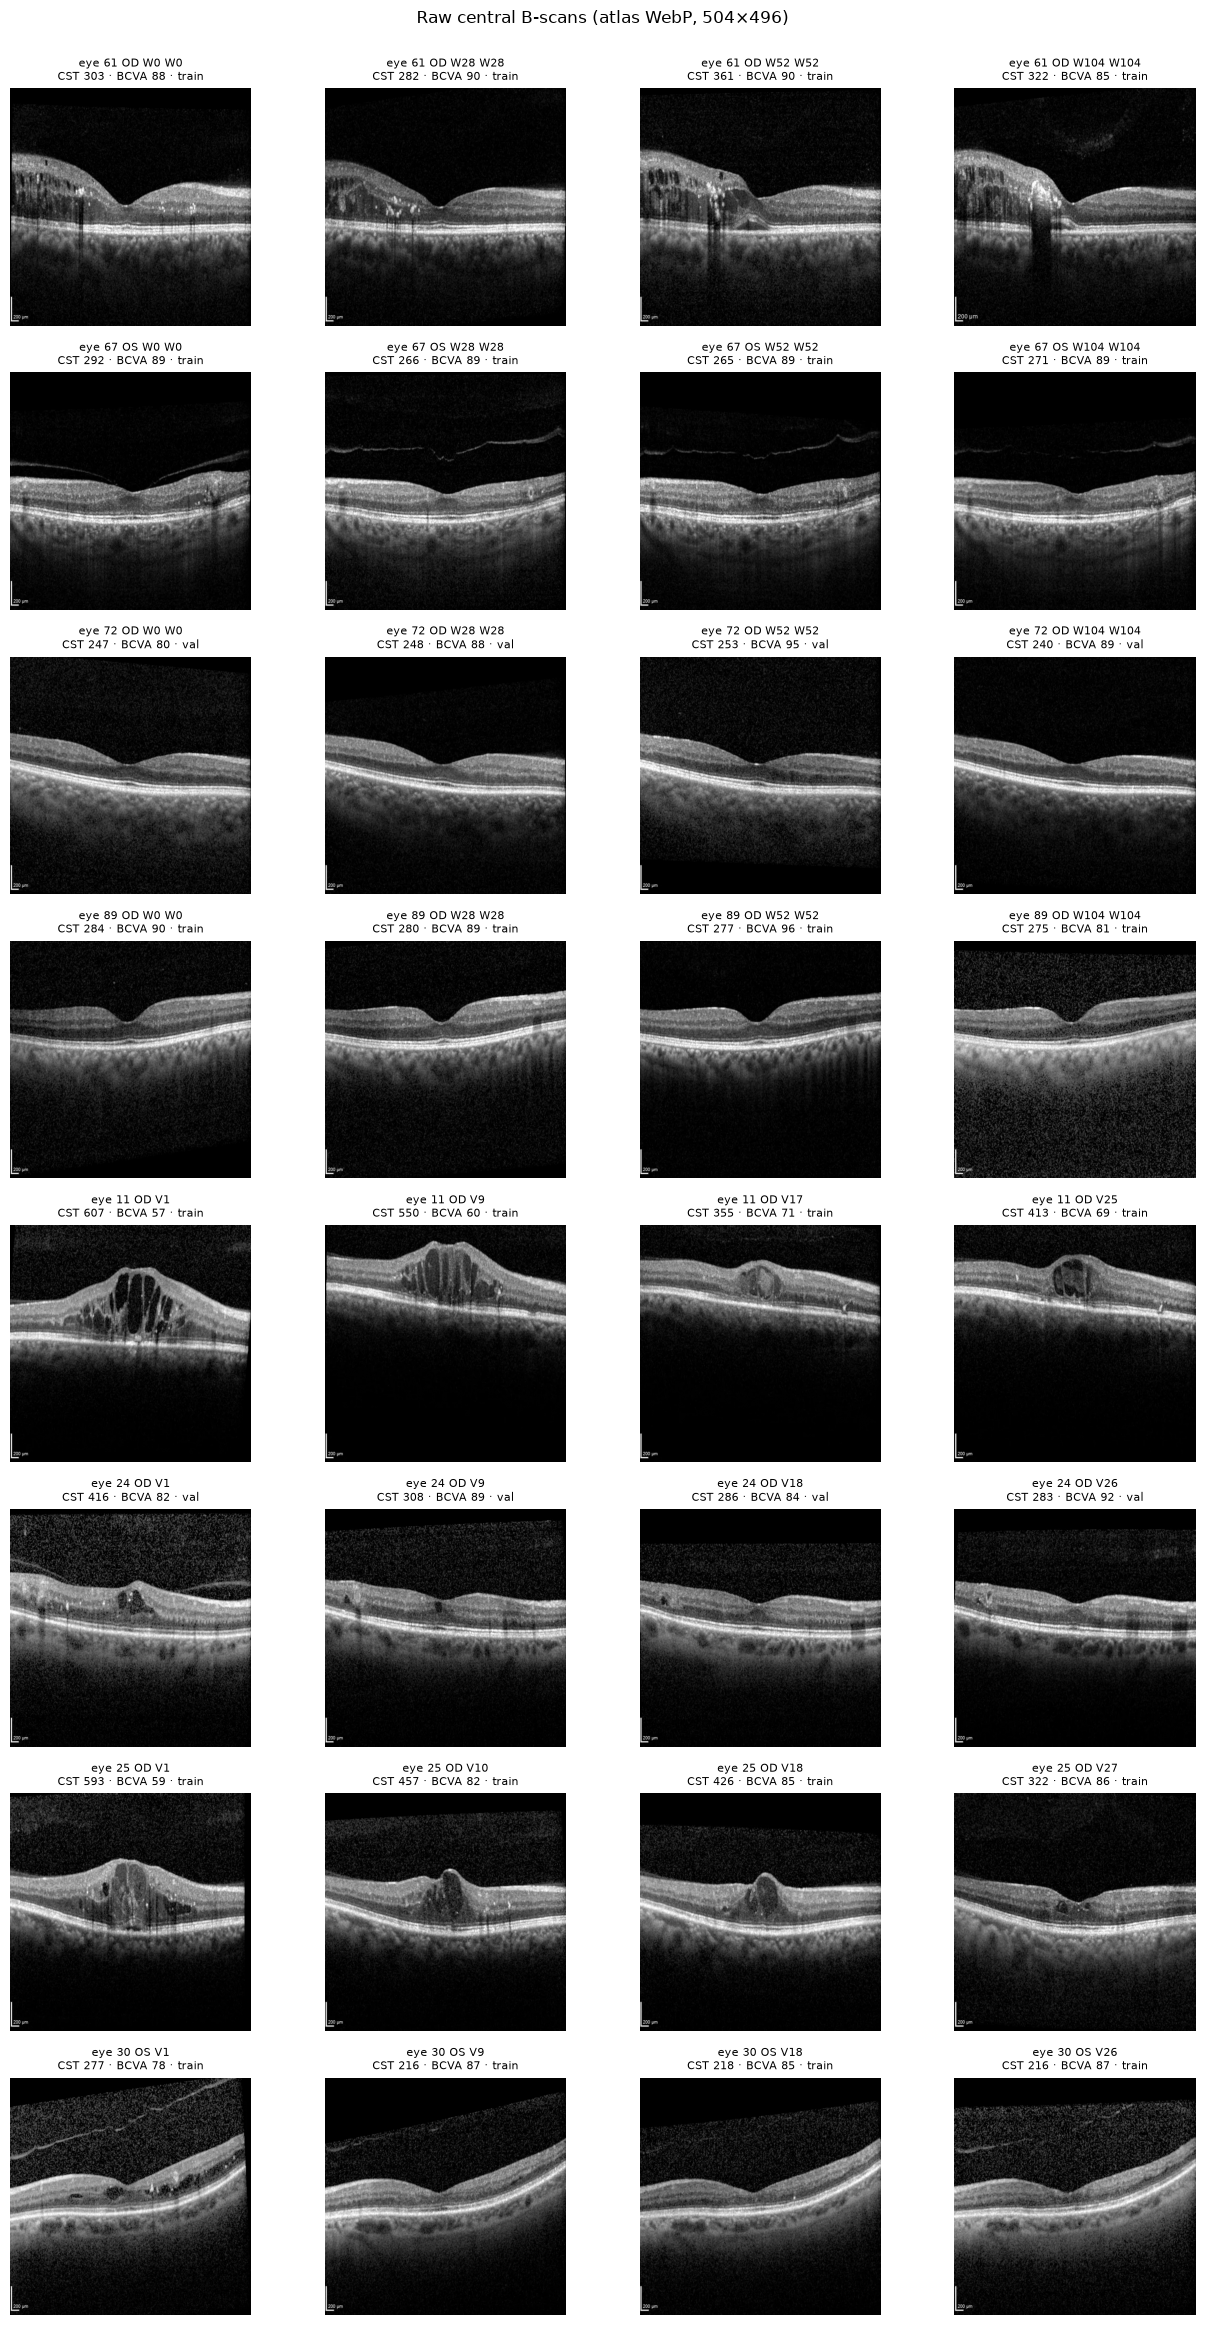

In [4]:
raw, info = {}, []
for r in m.itertuples():
    g, inf = OI.load_gray(SUBSET / r.local_path)
    raw[r.image_key] = g
    info.append(inf)
info = pd.DataFrame(info)
print("modes:", info["mode"].value_counts().to_dict(), "| sizes:", info.groupby(["width", "height"]).size().to_dict(),
      "| max RGB channel difference (grey levels):", int(info.max_channel_diff.max()))
allpix = np.stack(list(raw.values()))
print(f"intensity uint8: min {allpix.min()}, max {allpix.max()}, mean {allpix.mean():.1f}, std {allpix.std():.1f}")

centre = m[m.scan_index == 24]
eyes = list(dict.fromkeys(centre.eye_id))
fig, ax = plt.subplots(len(eyes), 4, figsize=(13, 2.9 * len(eyes)))
for i, e in enumerate(eyes):
    g = centre[centre.eye_id == e].sort_values("visit_index")
    for j, r in enumerate(g.itertuples()):
        ax[i, j].imshow(raw[r.image_key], cmap="gray", vmin=0, vmax=255)
        wk = "" if pd.isna(r.week) else f" W{int(r.week)}"
        ax[i, j].set_title(f"eye {e} {r.laterality} {r.visit_label}{wk}\nCST {r.cst:.0f} · BCVA {r.bcva:.0f} · {r.split}", fontsize=8)
        ax[i, j].axis("off")
plt.suptitle("Raw central B-scans (atlas WebP, 504×496)", y=1.0)
plt.tight_layout(); plt.savefig(OUT / "raw_grid.png", dpi=110, bbox_inches="tight"); plt.show()

## 5 · Preprocessing: resize and normalise (before/after)

The steps are grayscale uint8 → bicubic resize to 224×224 → scale /255 → replicate to 3 channels → ImageNet mean/std. Fixed /255 scaling (rather than per-image min-max) keeps real brightness differences between scans. The source aspect ratio is 504/496 = 1.016, so the square resize distorts by about 1.6 %. **Known artefact:** a burned-in scale bar sits at the bottom left of every scan; it is left in place and documented.

model input tensor: (96, 3, 224, 224) float32 | per-channel mean [-1.425 -1.328 -1.1  ], std [0.929 0.95  0.946]


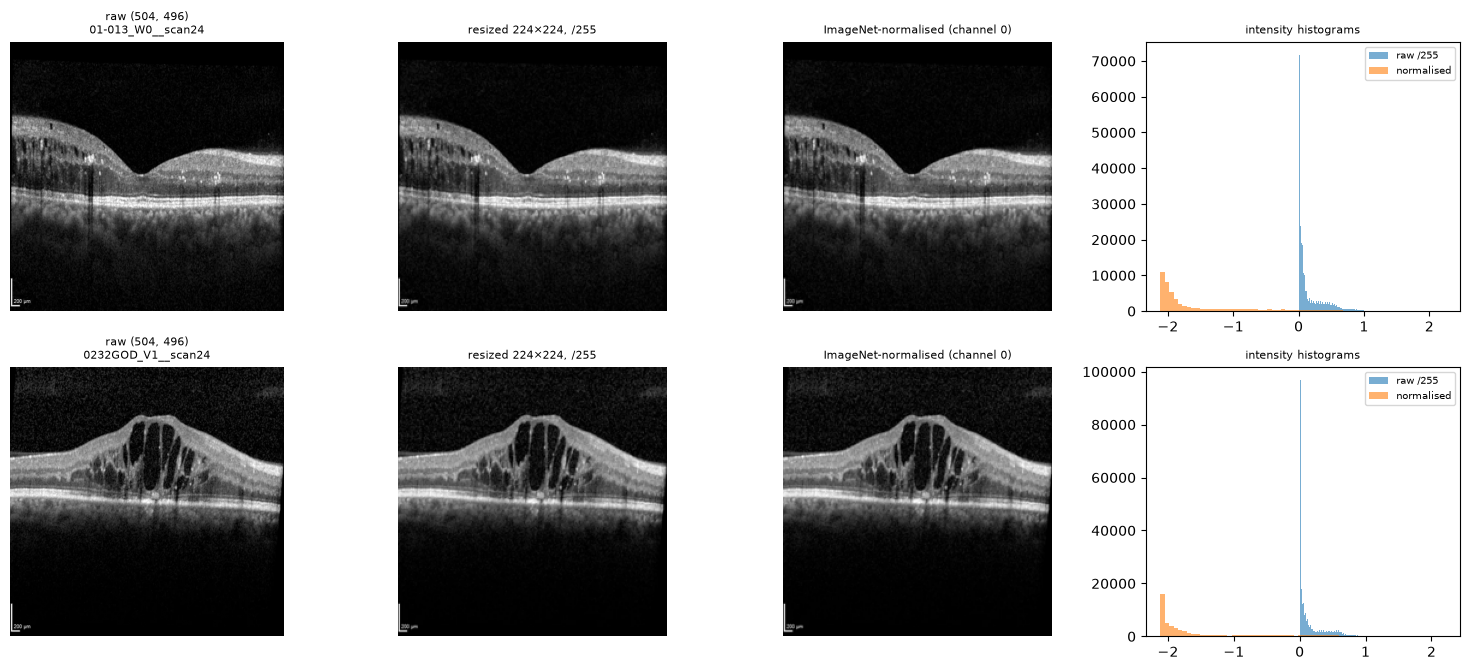

In [5]:
X, resized = [], {}
for r in m.itertuples():
    rs, x = OI.preprocess(raw[r.image_key])
    resized[r.image_key] = rs
    X.append(x)
X = np.stack(X)
print("model input tensor:", X.shape, X.dtype, f"| per-channel mean {X.mean((0, 2, 3)).round(3)}, std {X.std((0, 2, 3)).round(3)}")

ex = centre.sort_values(["trial", "eye_id"]).groupby("trial").head(1).image_key.tolist()
fig, ax = plt.subplots(len(ex), 4, figsize=(15, 3.4 * len(ex)))
for i, k in enumerate(ex):
    _, x = OI.preprocess(raw[k])
    ax[i, 0].imshow(raw[k], cmap="gray", vmin=0, vmax=255); ax[i, 0].set_title(f"raw {raw[k].shape[::-1]}\n{k}", fontsize=8)
    ax[i, 1].imshow(resized[k], cmap="gray", vmin=0, vmax=1); ax[i, 1].set_title("resized 224×224, /255", fontsize=8)
    ax[i, 2].imshow(x[0], cmap="gray"); ax[i, 2].set_title("ImageNet-normalised (channel 0)", fontsize=8)
    ax[i, 3].hist(raw[k].ravel() / 255, bins=64, alpha=.6, label="raw /255")
    ax[i, 3].hist(x[0].ravel(), bins=64, alpha=.6, label="normalised"); ax[i, 3].legend(fontsize=7)
    ax[i, 3].set_title("intensity histograms", fontsize=8)
    for a in ax[i, :3]: a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "preprocessing_before_after.png", dpi=110, bbox_inches="tight"); plt.show()

## 6 · Embeddings from a pretrained encoder

This cell checks the embedding shape, the absence of NaNs, and determinism (re-embedding a batch must give the same vectors).

In [6]:
import time
model, dim = OI.load_encoder(ENCODER, DEVICE)
t0 = time.time()
E = OI.embed(model, X, DEVICE)
secs = time.time() - t0
E2 = OI.embed(model, X[:8], DEVICE)
det = float(np.abs(E[:8] - E2).max())
print(f"embeddings {E.shape} (expected dim {dim}) | {secs:.1f}s on {DEVICE} | NaN: {np.isnan(E).any()} "
      f"| max |re-embed diff| = {det:.2e} | mean L2 norm {np.linalg.norm(E, axis=1).mean():.2f}")
assert E.shape == (len(m), dim) and not np.isnan(E).any() and det < 1e-3

embeddings (96, 2048) (expected dim 2048) | 14.6s on cpu | NaN: False | max |re-embed diff| = 0.00e+00 | mean L2 norm 11.98


## 7 · Cosine similarity, and the top-5 most similar scans for a query

The matrix is ordered by trial → eye → visit → scan. The sanity statistics compare how often the nearest neighbours share the query's eye, visit or trial with what random ranking would give. They only check that the embeddings carry patient-specific structure; they are **not** a clinical relevance measure.

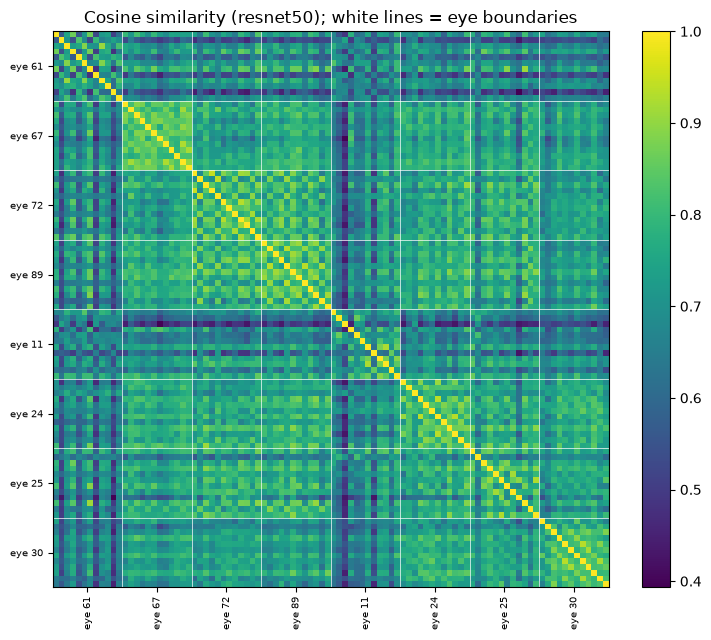

same eye in top-5: 0.623 (random 0.116) | top-1 is another scan of the same visit: 0.042 (random 0.021) | same trial in top-5: 0.823 (random 0.495)


In [7]:
S = OI.cosine_matrix(E)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(S, cmap="viridis"); plt.colorbar(im, fraction=.046)
b = np.flatnonzero(m.eye_id.to_numpy()[1:] != m.eye_id.to_numpy()[:-1]) + .5
for x in b: ax.axhline(x, color="w", lw=.5); ax.axvline(x, color="w", lw=.5)
ticks = m.groupby("eye_id", sort=False).apply(lambda g: g.index.to_numpy().mean())
ax.set_xticks(ticks.values, [f"eye {e}" for e in ticks.index], rotation=90, fontsize=7)
ax.set_yticks(ticks.values, [f"eye {e}" for e in ticks.index], fontsize=7)
ax.set_title(f"Cosine similarity ({ENCODER}); white lines = eye boundaries")
plt.tight_layout(); plt.savefig(OUT / "cosine_matrix.png", dpi=110, bbox_inches="tight"); plt.show()

ns = OI.neighbour_stats(S, m, k=5)
print(f"same eye in top-5: {ns.same_eye_at_k:.3f} (random {ns.same_eye_chance:.3f}) | "
      f"top-1 is another scan of the same visit: {ns.same_visit_at_1:.3f} (random {ns.same_visit_chance_at_1:.3f}) | "
      f"same trial in top-5: {ns.same_trial_at_k:.3f} (random {ns.same_trial_chance:.3f})")

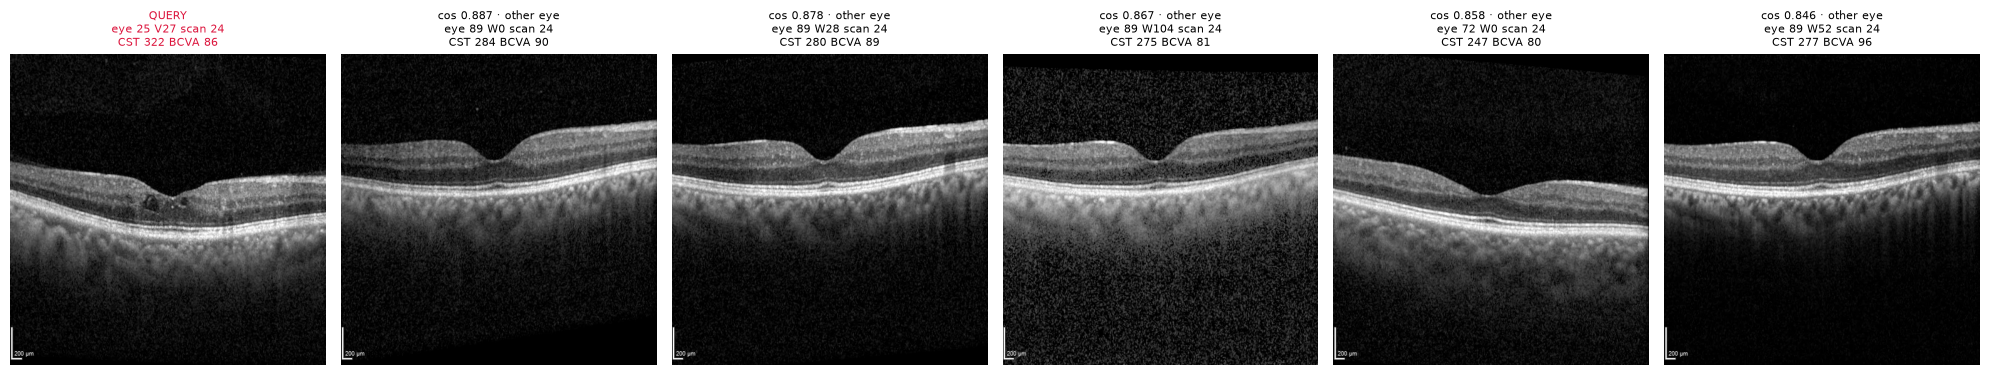

,image_key,eye_id,visit_label,scan_index,cst,bcva,cosine
37,02-036_W0__scan24,89,W0,24,284.0,90.0,0.8868
40,02-036_W28__scan24,89,W28,24,280.0,89.0,0.8782
46,02-036_W104__scan24,89,W104,24,275.0,81.0,0.8666
25,01-040_W0__scan24,72,W0,24,247.0,80.0,0.8579
43,02-036_W52__scan24,89,W52,24,277.0,96.0,0.8455


In [8]:
QUERY = "0210MOD_V27__scan24"          # change to any image_key from the manifest
q = int(np.flatnonzero(m.image_key == QUERY)[0])
nb = OI.topk(S, q, 5)
fig, ax = plt.subplots(1, 6, figsize=(20, 3.6))
def lab(r): return f"eye {r.eye_id} {r.visit_label} scan {r.scan_index}\nCST {r.cst:.0f} BCVA {r.bcva:.0f}"
ax[0].imshow(raw[m.image_key[q]], cmap="gray"); ax[0].set_title("QUERY\n" + lab(m.iloc[q]), fontsize=8, color="crimson")
for a, i in zip(ax[1:], nb):
    r = m.iloc[i]
    a.imshow(raw[r.image_key], cmap="gray")
    same = "same eye" if r.eye_id == m.eye_id[q] else "other eye"
    a.set_title(f"cos {S[q, i]:.3f} · {same}\n" + lab(r), fontsize=8)
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(OUT / f"top5_{QUERY}.png", dpi=110, bbox_inches="tight"); plt.show()
display(m.iloc[nb][["image_key", "eye_id", "visit_label", "scan_index", "cst", "bcva"]].assign(cosine=S[q, nb].round(4)))

## 8 · Save embeddings and identifiers

`embeddings.npz` holds the float32 embeddings plus the `image_key` order. `embedding_index.csv` holds the identifiers, one row per embedding row. In Colab, the last line zips the outputs for download.

In [9]:
np.savez(OUT / "embeddings.npz", embeddings=E.astype(np.float32), image_key=m.image_key.to_numpy().astype(str),
         encoder=np.array(ENCODER))
m[["image_key", "visit_id", "eye_id", "patient_id", "subject", "trial", "split", "laterality", "visit_label",
   "visit_index", "week", "scan_index", "cst", "bcva", "archive_path", "atlas_id", "sha256"]].to_csv(OUT / "embedding_index.csv", index=False)
run_info = dict(encoder=ENCODER, dim=int(E.shape[1]), n=len(m), device=str(DEVICE), seconds=round(secs, 2),
                torch=torch.__version__, torchvision=torchvision.__version__, python=platform.python_version(),
                in_colab=IN_COLAB, determinism_max_abs_diff=det, neighbour_stats=ns.__dict__)
(OUT / "run_info.json").write_text(json.dumps(run_info, indent=2))
print("saved to", OUT, sorted(p.name for p in OUT.iterdir()))
if IN_COLAB:
    shutil.make_archive(f"/content/phase2_results_{ENCODER}", "zip", OUT)
    print(f"download /content/phase2_results_{ENCODER}.zip (Files pane) or run: files.download(...)")

saved to C:\question aware retinal oct reasoning\phase2\results\resnet50 ['cosine_matrix.png', 'embedding_index.csv', 'embeddings.npz', 'image_vs_metadata_per_query.csv', 'image_vs_metadata_summary.json', 'preprocessing_before_after.png', 'raw_grid.png', 'run_info.json', 'top5_0210MOD_V27__scan24.png', 'visit_pairs.csv']


## 9 · Preliminary integration: image-based vs metadata-based ranking of prior visits

This section uses the frozen Phase 1 parser and retriever **read-only**. For each eye, the history is restricted to the 4 subset visits; each later visit acts as the "current" visit and its earlier subset visits are the candidates. The output reports how often the image ranking's top-1 agrees with each metadata question's top-1, against chance. It also shows the frozen system's outcome for an image question and what the prototype hybrid router does with it. **There is no ground truth here: agreement is not accuracy.**

In [10]:
import importlib, image_vs_metadata as IVM
importlib.reload(IVM)
s = IVM.run(OUT / "embeddings.npz", SUBSET, OUT)
print(json.dumps(s, indent=2))
pq = pd.read_csv(OUT / "image_vs_metadata_per_query.csv")
display(pq[["query_visit", "t", "image_top1", "closest_cst_top1", "closest_bcva_top1", "previous_top1",
            "image_like_status", "hybrid_status", "hybrid_top1"]])

{
  "identical_image_content_across_visits": [],
  "setting": "subset-restricted history (not the full Phase 1 history); agreement only, no ground truth; not an evaluation",
  "histories_complete": false,
  "encoder": "resnet50",
  "n_eyes": 8,
  "n_visits": 32,
  "n_queries_total": 24,
  "parsed": {
    "closest_cst": {
      "operation": "closest_to_current",
      "target": "cst",
      "task": "retrieve"
    },
    "closest_bcva": {
      "operation": "closest_to_current",
      "target": "bcva",
      "task": "retrieve"
    },
    "previous": {
      "operation": "anchor_previous",
      "target": null,
      "task": "retrieve"
    },
    "baseline": {
      "operation": "anchor_baseline",
      "target": null,
      "task": "retrieve"
    },
    "image_like": {
      "operation": null,
      "target": null,
      "task": "unsupported_image"
    }
  },
  "top1_agreement_n_queries": 16,
  "top1_agreement_chance": 0.417,
  "top1_agreement_image_vs": {
    "closest_cst": 0.5,
    "cl

,query_visit,t,image_top1,closest_cst_top1,closest_bcva_top1,previous_top1,image_like_status,hybrid_status,hybrid_top1
0,0232GOD_V9,1,0232GOD_V1,0232GOD_V1,0232GOD_V1,0232GOD_V1,unsupported_image,image_retrieved,0232GOD_V1
1,0232GOD_V17,2,0232GOD_V9,0232GOD_V9,0232GOD_V9,0232GOD_V9,unsupported_image,image_retrieved,0232GOD_V9
2,0232GOD_V25,3,0232GOD_V17,0232GOD_V17,0232GOD_V17,0232GOD_V17,unsupported_image,image_retrieved,0232GOD_V17
3,0206MOD_V9,1,0206MOD_V1,0206MOD_V1,0206MOD_V1,0206MOD_V1,unsupported_image,image_retrieved,0206MOD_V1
4,0206MOD_V18,2,0206MOD_V9,0206MOD_V9,0206MOD_V1,0206MOD_V9,unsupported_image,image_retrieved,0206MOD_V9
5,0206MOD_V26,3,0206MOD_V18,0206MOD_V18,0206MOD_V9,0206MOD_V18,unsupported_image,image_retrieved,0206MOD_V18
6,0210MOD_V10,1,0210MOD_V1,0210MOD_V1,0210MOD_V1,0210MOD_V1,unsupported_image,image_retrieved,0210MOD_V1
7,0210MOD_V18,2,0210MOD_V10,0210MOD_V10,0210MOD_V10,0210MOD_V10,unsupported_image,image_retrieved,0210MOD_V10
8,0210MOD_V27,3,0210MOD_V10,0210MOD_V18,0210MOD_V18,0210MOD_V18,unsupported_image,image_retrieved,0210MOD_V10
9,0222MOS_V9,1,0222MOS_V1,0222MOS_V1,0222MOS_V1,0222MOS_V1,unsupported_image,image_retrieved,0222MOS_V1


## 9b · Full-history comparison (3 train eyes, every visit, central B-scan)

The full-history subset holds eyes 25 and 11 (TREX) and 61 (Prime): 73 visits, one central scan each, verified the same way. Here the visit memory is **identical to Phase 1's** for these eyes, and the script asserts this. Partial correlations control for the time gap, because CST/BCVA closeness also tracks recency. **Known data issue:** the atlas serves byte-identical volumes for `01-013` W8 and W12, and the summary reports it under `identical_image_content_across_visits`.

{
 "setting": "full visit history of each eye (memory identical to Phase 1); agreement only, no ground truth; not an evaluation",
 "identical_image_content_across_visits": [
  [
   "01-013_W12",
   "01-013_W8"
  ]
 ],
 "top1_agreement_n_queries": 67,
 "top1_agreement_chance": 0.123,
 "top1_agreement_image_vs": {
  "closest_cst": 0.179,
  "closest_bcva": 0.269,
  "previous": 0.299,
  "baseline": 0.104
 },
 "mean_spearman_image_vs": {
  "closest_cst": 0.394,
  "closest_bcva": 0.289,
  "previous": 0.477,
  "baseline": -0.477
 },
 "mean_norm_rank_of_metadata_top1_in_image_ranking": {
  "closest_cst": 0.379,
  "closest_bcva": 0.34,
  "previous": 0.298,
  "baseline": 0.724
 },
 "image_top1_is_previous_visit": 0.299,
 "hybrid_answered_by_image": 70,
 "within_eye_pairs_by_eye": {
  "11": {
   "n_pairs": 300,
   "partial_cst_given_gap": 0.45,
   "partial_bcva_given_gap": 0.072,
   "cos_vs_minus_abs_d_cst": 0.524,
   "cos_vs_minus_abs_d_bcva": 0.12,
   "cos_vs_minus_gap_positions": 0.323
  },
  

C:\question aware retinal oct reasoning\phase2\results\fullhist\resnet50\fullhist_eyes.png


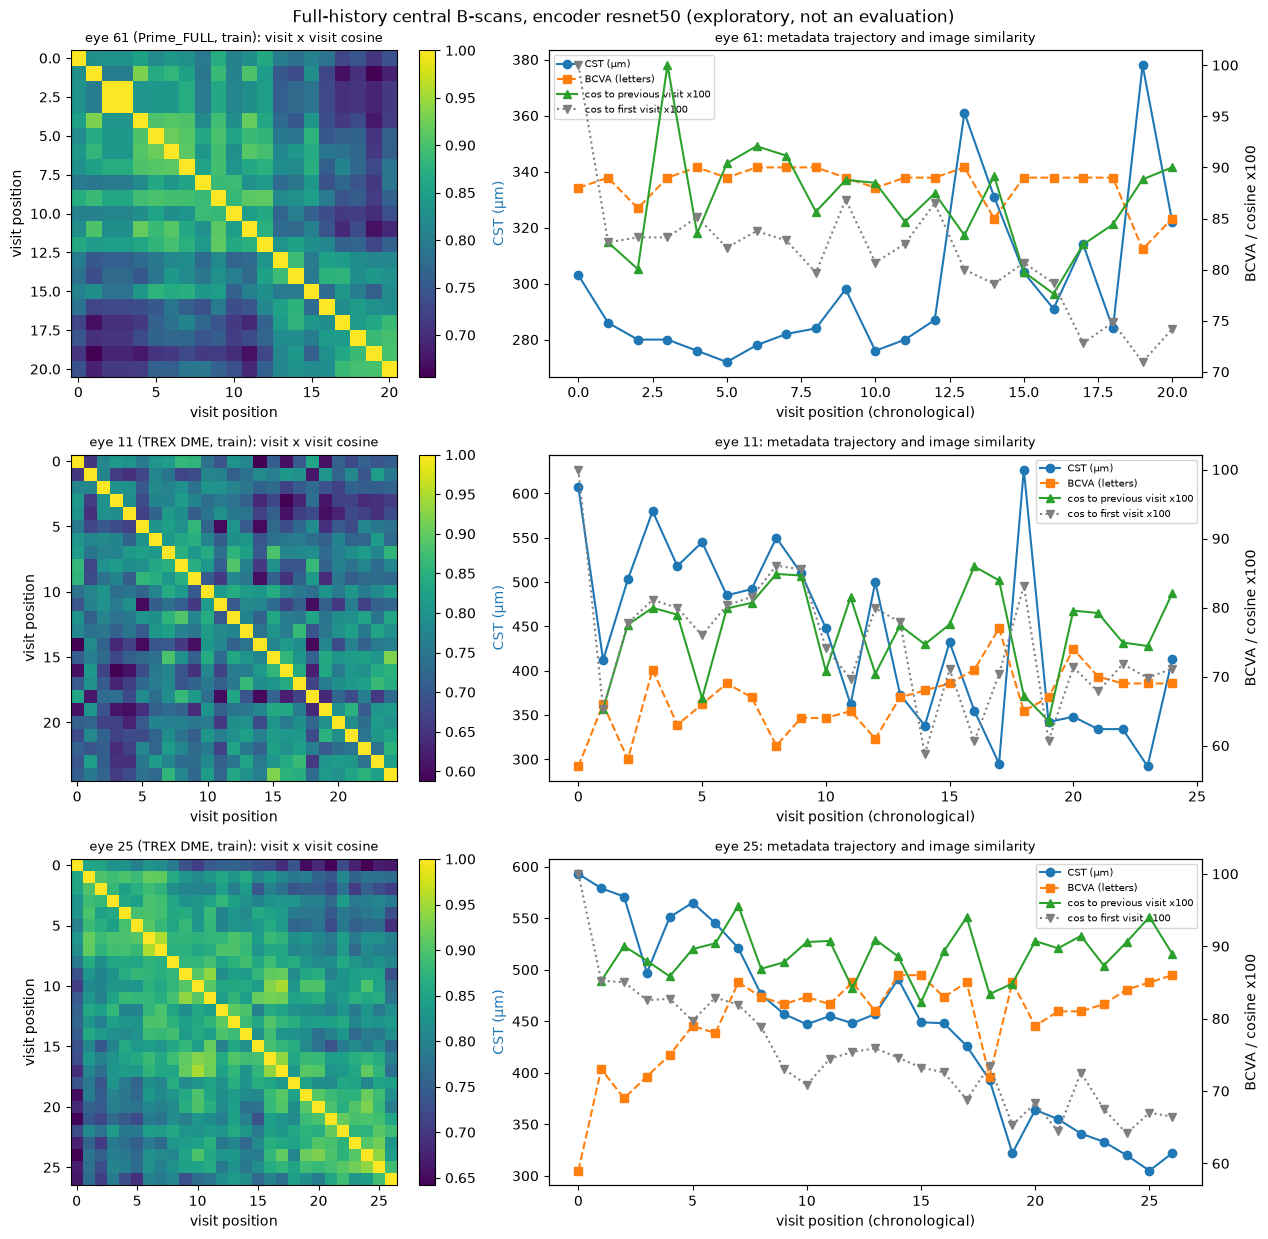

In [11]:
FULL = ROOT / "phase2" / "data" / "atlas_fullhist"
OUT_FULL = ROOT / "phase2" / "results" / "fullhist" / ENCODER
OUT_FULL.mkdir(parents=True, exist_ok=True)
mf = OI.load_manifest(FULL)
assert OI.verify_checksums(mf, FULL).all()
Xf = np.stack([OI.preprocess(OI.load_gray(FULL / p)[0])[1] for p in mf.local_path])
Ef = OI.embed(model, Xf, DEVICE)
np.savez(OUT_FULL / "embeddings.npz", embeddings=Ef.astype(np.float32), image_key=mf.image_key.to_numpy().astype(str),
         encoder=np.array(ENCODER))
sf = IVM.run(OUT_FULL / "embeddings.npz", FULL, OUT_FULL)
keys = ["setting", "identical_image_content_across_visits", "top1_agreement_n_queries", "top1_agreement_chance",
        "top1_agreement_image_vs", "mean_spearman_image_vs", "mean_norm_rank_of_metadata_top1_in_image_ranking",
        "image_top1_is_previous_visit", "hybrid_answered_by_image", "within_eye_pairs_by_eye"]
print(json.dumps({k: sf[k] for k in keys}, indent=1))
import plot_fullhist, importlib
importlib.reload(plot_fullhist)
plot_fullhist.main(["--emb", str(OUT_FULL / "embeddings.npz"), "--subset", str(FULL)])
from IPython.display import Image as IPImage
display(IPImage(filename=str(OUT_FULL / "fullhist_eyes.png")))

## 10 · Status and limitations (read before presenting)

- **Works:** real B-scans are loaded with verified identifiers; preprocessing; pretrained embeddings (GPU or CPU); cosine top-k; saved embeddings; a read-only bridge to the Phase 1 retriever; and a hybrid route for questions Phase 1 marks `unsupported_image`.
- **Partly done:** full histories for 3 train eyes (section 9b). The other eyes have only 4 of their 21–27 visits.
- **Pending:**
  - A domain-specific encoder (e.g. RETFound, once its access and licence are verified).
  - A byte-level check against the official Zenodo archive.
  - A **pre-registered** evaluation with relevance labels for image questions.
- Nothing here is clinically validated. Agreement and sanity statistics are not retrieval accuracy.